In [1]:
!pip install matplotlib

In [2]:
# Setup: imports, repo paths, shared colors, and plot defaults.
# GRID_FILE selects accuracy_by_dialect.tsv or accuracy_by_dialect_llm.tsv.
%config InlineBackend.figure_formats = ["svg"]  # vector figures in the notebook
import json
from pathlib import Path


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.font_manager import FontProperties
from matplotlib.ticker import FuncFormatter, NullLocator, PercentFormatter
from matplotlib.transforms import Bbox


def find_repo_root(start: Path) -> Path:
    """Find the folder that holds the benchmark summaries."""
    for path in (start, *start.parents):
        if (path / "accuracy_by_dialect.tsv").exists():
            return path
    raise FileNotFoundError(f"accuracy_by_dialect.tsv not found above {start}")


ROOT = find_repo_root(Path.cwd())
GRID_FILE = ROOT / "accuracy_by_dialect_llm.tsv"  # LLM-judged corrections

DE_COLOR = "#2E5EAA"
DIALECT_COLOR = "#E07B39"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
    "svg.fonttype": "none",  # keep text editable/selectable in SVG output
})

In [3]:
# Load the accuracy grid and compute de vs. dialect mean for each run.
grid = pd.read_csv(GRID_FILE, sep="\t")
dialect_cols = [c for c in grid.columns if c.startswith("mgsm_")]

acc = pd.DataFrame({
    "model": grid["model"],
    "thinking": grid["thinking"].str.removeprefix("thinking-"),
    "de": grid["de"],
    "dialects": grid[dialect_cols].mean(axis=1, skipna=True),
})
acc[dialect_cols] = grid[dialect_cols]
acc["gap"] = acc["de"] - acc["dialects"]

# Add the thinking mode only when a model was run in both modes.
both_modes = acc["model"].duplicated(keep=False)
acc["label"] = np.where(both_modes, acc["model"] + " (" + acc["thinking"] + ")", acc["model"])
# Display name: the Codex runs are labelled ChatGPT in the figures (model IDs stay unchanged
# so the joins with run_info.jsonl keep working).
acc["label"] = acc["label"].str.replace("codex-", "chatgpt-", regex=False)

# Worst dialect accuracy first; this order is reused in the heatmap below.
acc = acc.sort_values(["dialects", "de"], ascending=True).reset_index(drop=True)

print(f"{len(acc)} runs from {acc['model'].nunique()} models")
print(f"mean accuracy drop from de to dialects: {acc['gap'].mean():.1%}")
print(f"runs with a higher de accuracy: {(acc['gap'] > 0).sum()} of {len(acc)}")

44 runs from 30 models
mean accuracy drop from de to dialects: 10.9%
runs with a higher de accuracy: 43 of 44


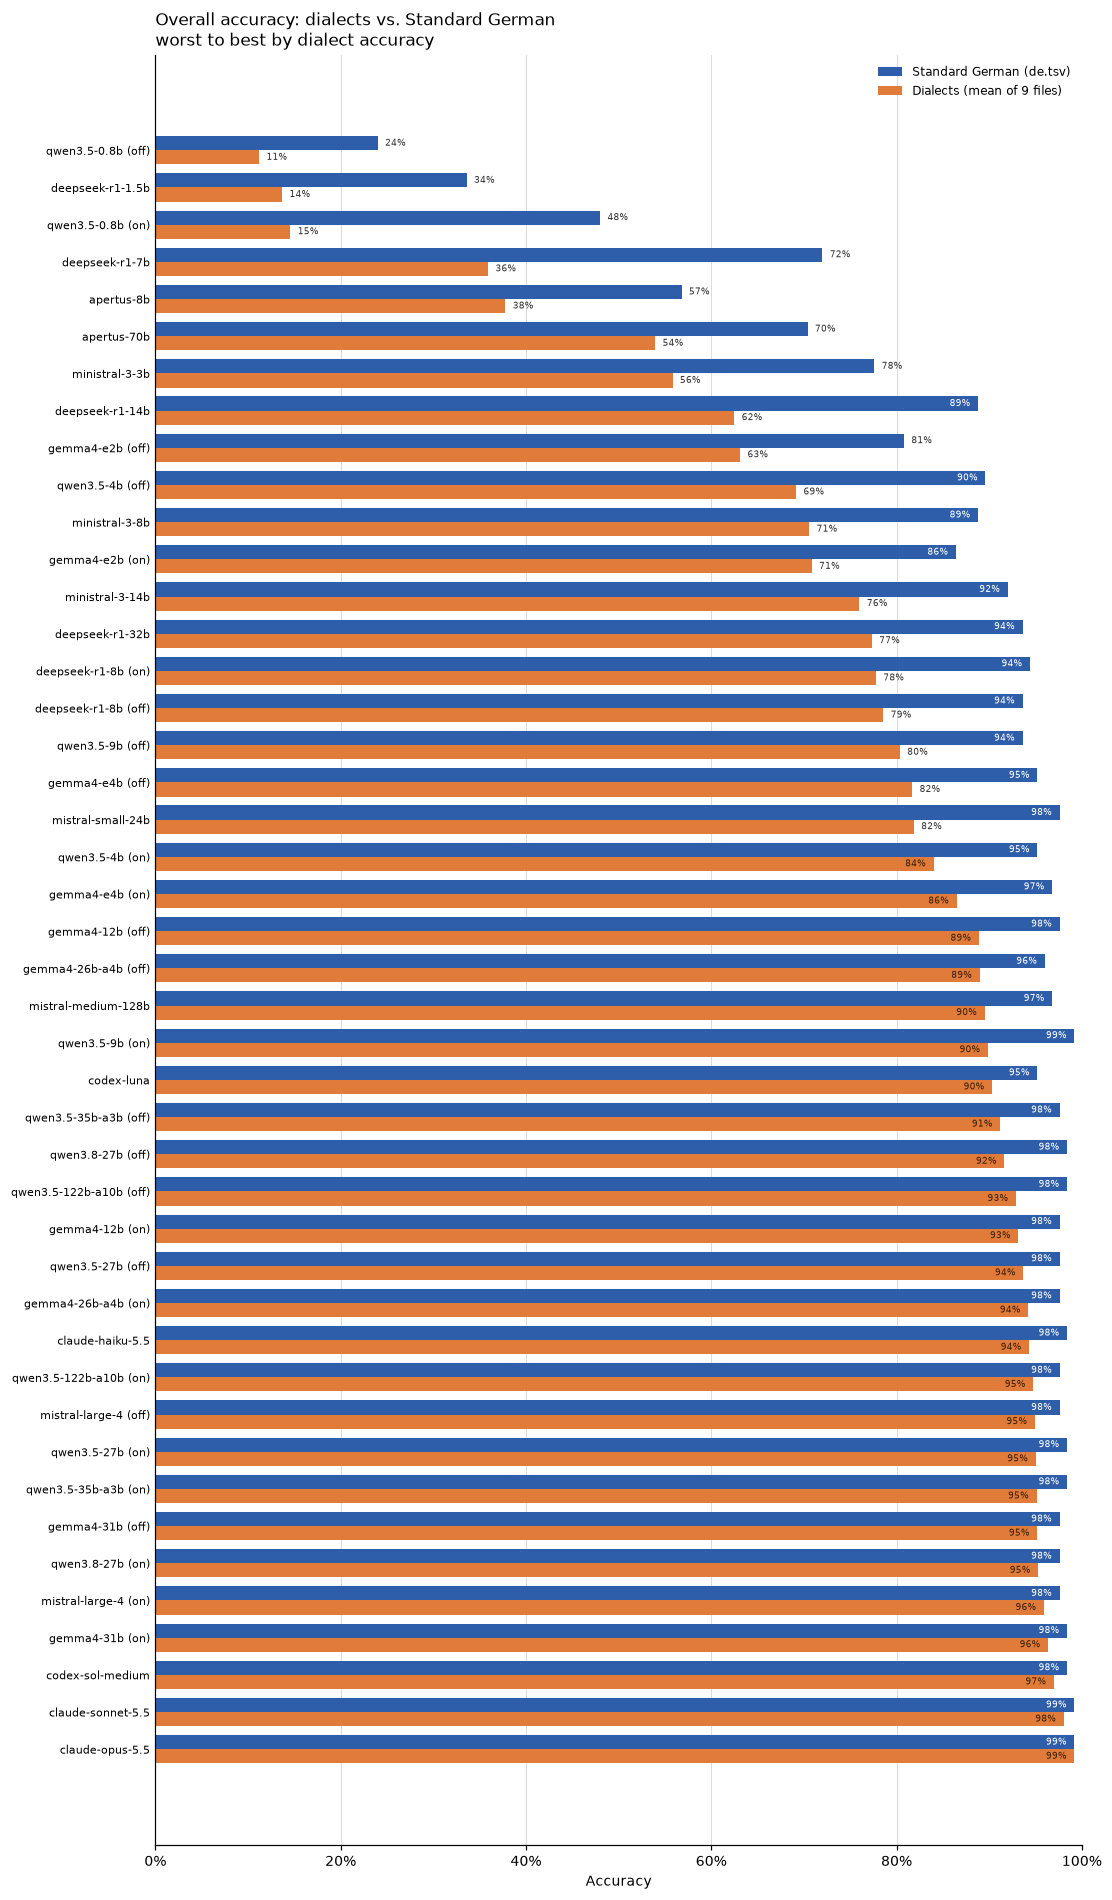

In [4]:
# Chart 1: overall accuracy per run, sorted worst to best, de vs. dialects.
fig, ax = plt.subplots(figsize=(10, 0.34 * len(acc) + 2.2), layout="constrained")

y = np.arange(len(acc))
bar_height = 0.38

de_bars = ax.barh(y - bar_height / 2, acc["de"], height=bar_height, color=DE_COLOR,
                  label="Standard German (de.tsv)")
dialect_bars = ax.barh(y + bar_height / 2, acc["dialects"], height=bar_height, color=DIALECT_COLOR,
                       label="Dialects (mean of 9 files)")

for bars, values, inside_color in (
    (de_bars, acc["de"], "white"),
    (dialect_bars, acc["dialects"], "#3D1F08"),
):
    for bar, value in zip(bars, values):
        inside = value > 0.82
        ax.text(
            value - 0.008 if inside else value + 0.008,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.0%}",
            va="center",
            ha="right" if inside else "left",
            fontsize=6.2,
            color=inside_color if inside else "#333333",
        )

ax.set_yticks(y)
ax.set_yticklabels(acc["label"], fontsize=7.2)
ax.invert_yaxis()  # worst run at the top, best at the bottom
ax.set_xlim(0, 1)
ax.set_xlabel("Accuracy")
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.grid(axis="x", color="#D9D9D9", linewidth=0.6)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.set_title("Overall accuracy: dialects vs. Standard German\nworst to best by dialect accuracy",
             loc="left", fontsize=11)
ax.legend(loc="upper right", frameon=False, fontsize=8)

plt.show()

saved images/accuracy_divergence.svg


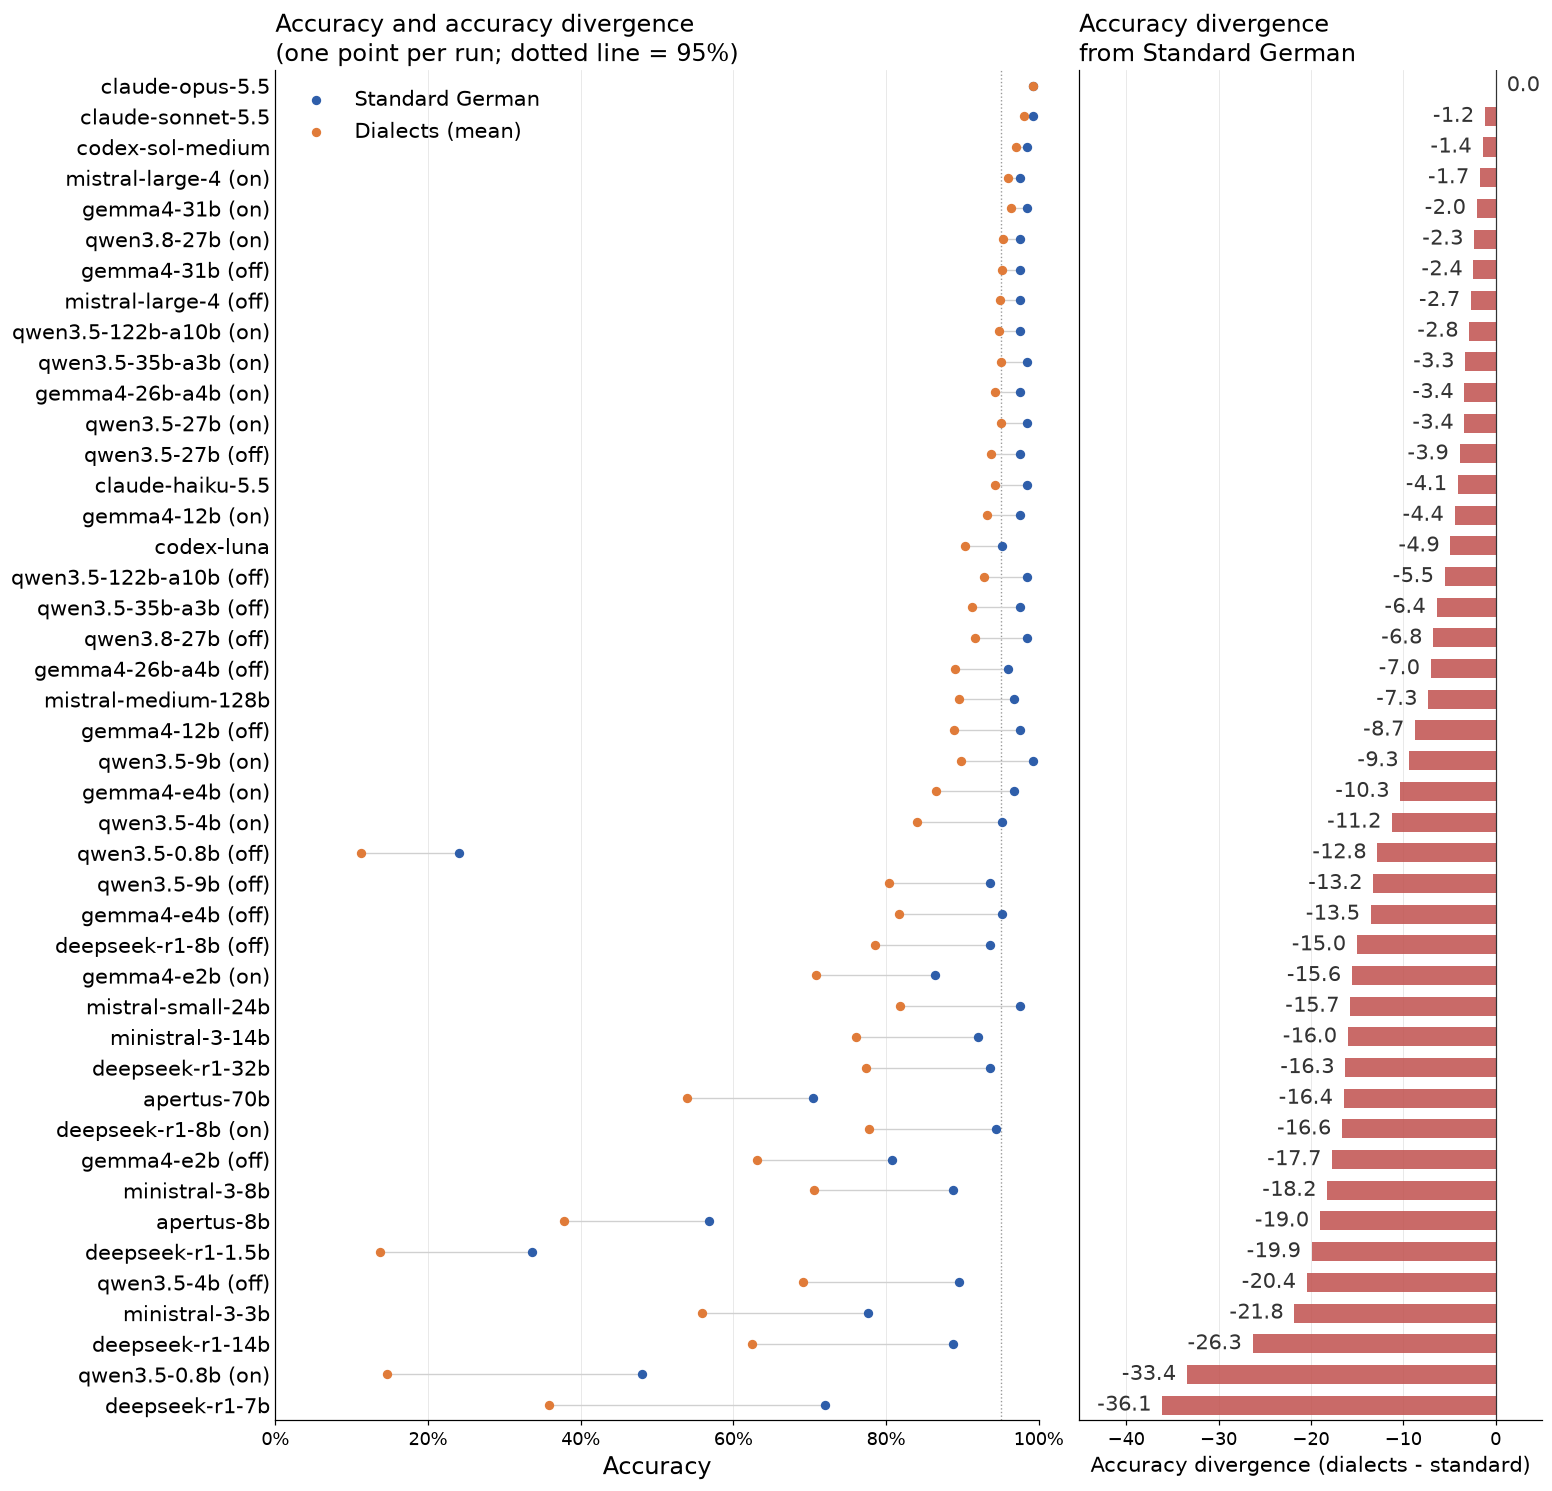

In [24]:
# Chart 1b: accuracy level and accuracy divergence, sorted by divergence.
# Every run is shown, with thinking-on and thinking-off kept separate.
pen = acc.copy()
pen["divergence_pp"] = (pen["dialects"] - pen["de"]) * 100
pen = pen.sort_values(["divergence_pp", "dialects"], ascending=[False, False]).reset_index(drop=True)

y = np.arange(len(pen))
div_min = pen["divergence_pp"].min()
div_max = pen["divergence_pp"].max()

fig, (ax_acc, ax_gap) = plt.subplots(
    1, 2, figsize=(14, 0.26 * len(pen) + 2.0), sharey=True,
    gridspec_kw={"width_ratios": [1.65, 1]}, layout="constrained",
)

# Left: de -> dialect dumbbell.
ax_acc.hlines(y, pen["dialects"], pen["de"], color="#D0D0D0", linewidth=0.9, zorder=1)
ax_acc.scatter(pen["de"], y, s=26, color=DE_COLOR, zorder=3, label="Standard German")
ax_acc.scatter(pen["dialects"], y, s=26, color=DIALECT_COLOR, zorder=3, label="Dialects (mean)")
ax_acc.axvline(0.95, color="#999999", linestyle=":", linewidth=0.9, zorder=0)
ax_acc.set_xlim(0, 1)
ax_acc.set_xlabel("Accuracy", fontsize=16)
ax_acc.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax_acc.grid(axis="x", color="#E3E3E3", linewidth=0.5)
ax_acc.set_axisbelow(True)
ax_acc.legend(loc="upper left", frameon=False, fontsize=14)

# Right: dialect accuracy minus German accuracy, in percentage points.
colors = np.where(pen["divergence_pp"] >= 0, "#2E5EAA", "#C0504D")
ax_gap.barh(y, pen["divergence_pp"], height=0.62, color=colors, alpha=0.85)
ax_gap.axvline(0, color="#333333", linewidth=0.8)
ax_gap.set_xlim(div_min - 9, max(0, div_max + 5))
ax_gap.set_xlabel("Accuracy divergence (dialects - standard)", fontsize=14)
ax_gap.grid(axis="x", color="#E3E3E3", linewidth=0.5)
ax_gap.set_axisbelow(True)
ax_gap.tick_params(axis="y", left=False, labelleft=False)
ax_gap.tick_params(axis="x", labelsize=12)
ax_acc.tick_params(axis="x", labelsize=12)

for yi, value in zip(y, pen["divergence_pp"]):
    pad = 1.2 if value >= 0 else -1.2
    label = "0.0" if abs(value) < 0.05 else f"{value:+.1f}"
    ax_gap.text(value + pad, yi, label, va="center",
                ha="left" if value >= 0 else "right", fontsize=14,
                color="#333333")

ax_acc.set_yticks(y)
ax_acc.set_yticklabels(pen["label"], fontsize=14)
ax_acc.tick_params(axis="y", length=0)
ax_acc.set_ylim(len(pen) - 0.5, -0.5)
ax_acc.set_title("Accuracy and accuracy divergence\n(one point per run; dotted line = 95%)",
                 loc="left", fontsize=16)
ax_gap.set_title("Accuracy divergence\nfrom Standard German", loc="left", fontsize=16)

svg_path = ROOT / "images" / "accuracy_divergence.svg"
svg_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(svg_path, bbox_inches="tight")
print(f"saved {svg_path.relative_to(ROOT)}")

plt.show()


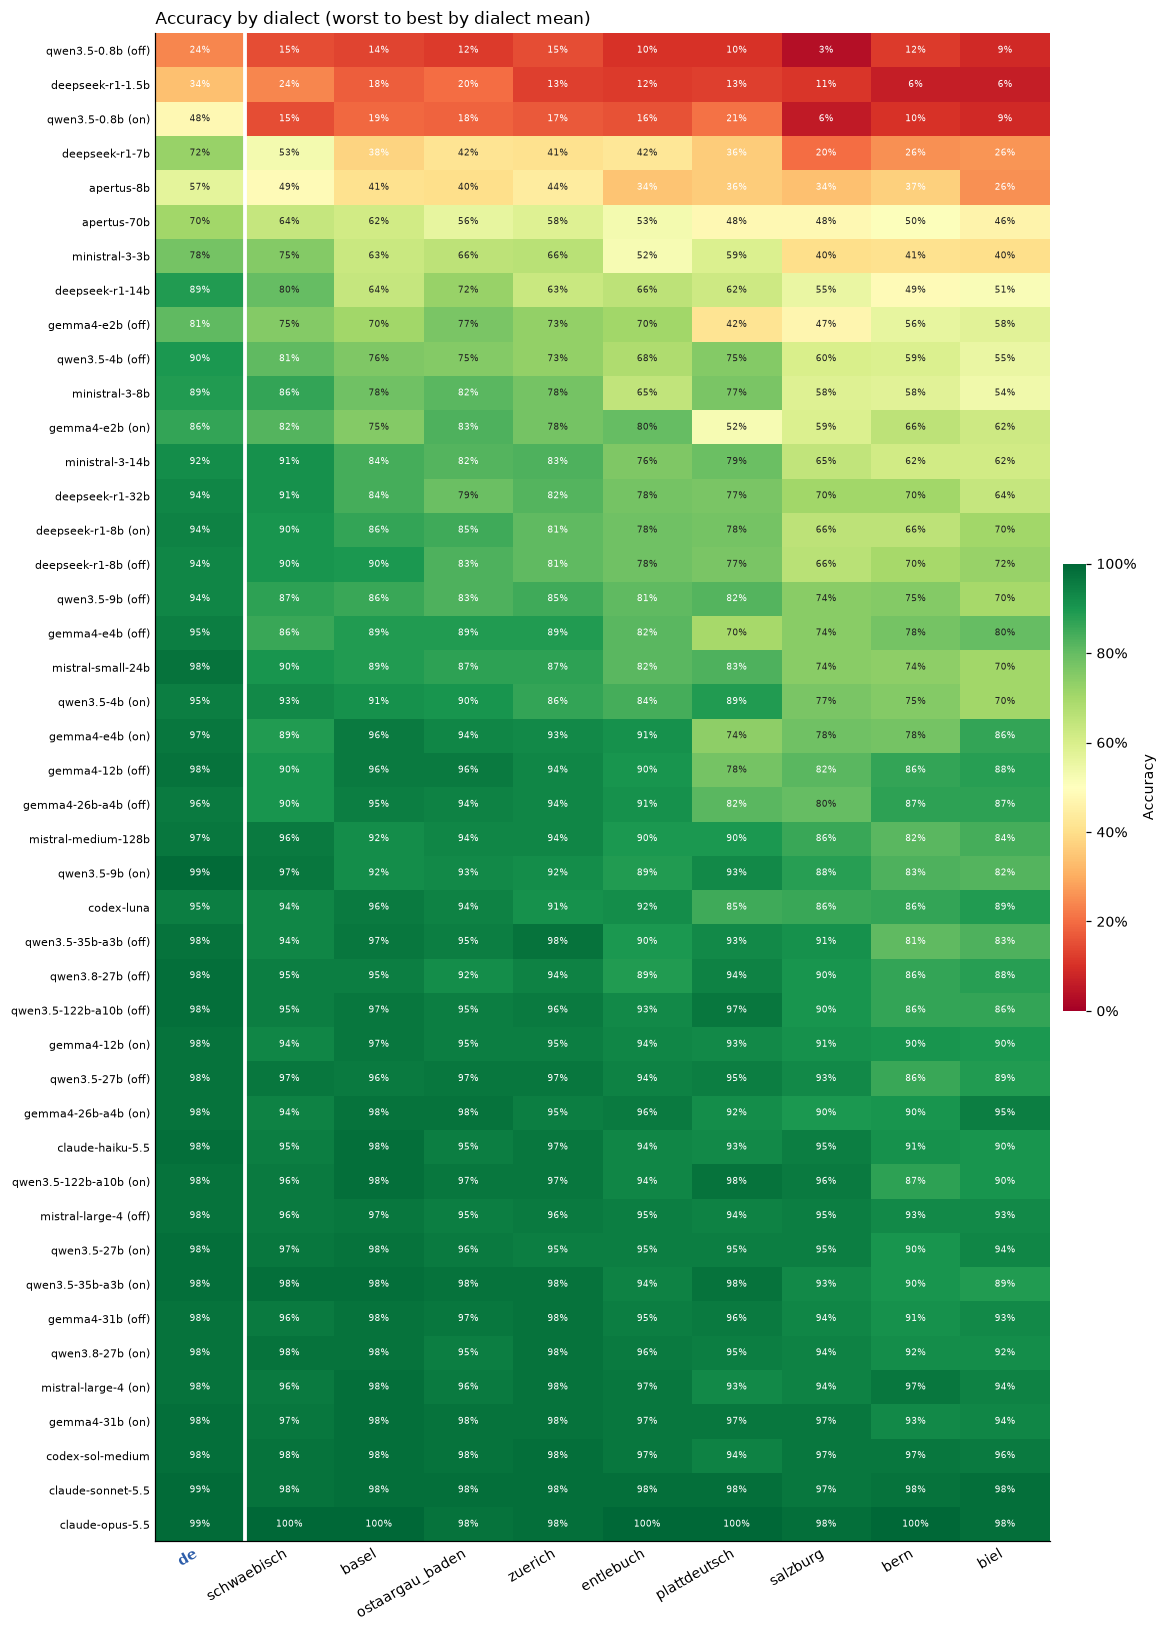

In [6]:
# Chart 2: accuracy per dialect (de first), rows in the order of chart 1.
dialect_order = grid[dialect_cols].mean().sort_values(ascending=False).index.tolist()
column_order = ["de", *dialect_order]
heat = acc.set_index("label")[column_order]

cmap = plt.get_cmap("RdYlGn").copy()
cmap.set_bad("#E6E6E6")

fig, ax = plt.subplots(figsize=(10.5, 0.28 * len(heat) + 2.4), layout="constrained")
image = ax.imshow(heat.to_numpy(dtype=float), aspect="auto", cmap=cmap, vmin=0, vmax=1)

ax.set_xticks(range(len(column_order)))
ax.set_xticklabels(
    ["de" if c == "de" else c.removeprefix("mgsm_").removesuffix("_complete") for c in column_order],
    rotation=30,
    ha="right",
)
ax.set_yticks(range(len(heat)))
ax.set_yticklabels(heat.index, fontsize=7)
ax.tick_params(axis="both", length=0)

for tick, column in zip(ax.get_xticklabels(), column_order):
    if column == "de":
        tick.set_color(DE_COLOR)
        tick.set_fontweight("bold")

for row in range(heat.shape[0]):
    for col in range(heat.shape[1]):
        value = heat.iat[row, col]
        if pd.notna(value):
            ax.text(
                col, row, f"{value:.0%}",
                ha="center", va="center", fontsize=6,
                color="white" if value < 0.4 or value > 0.8 else "#222222",
            )

ax.axvline(0.5, color="white", linewidth=2.5)
ax.set_title("Accuracy by dialect (worst to best by dialect mean)", loc="left", fontsize=11)

colorbar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.015)
colorbar.set_label("Accuracy")
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
colorbar.outline.set_visible(False)

plt.show()

saved images/dialect_differences.svg


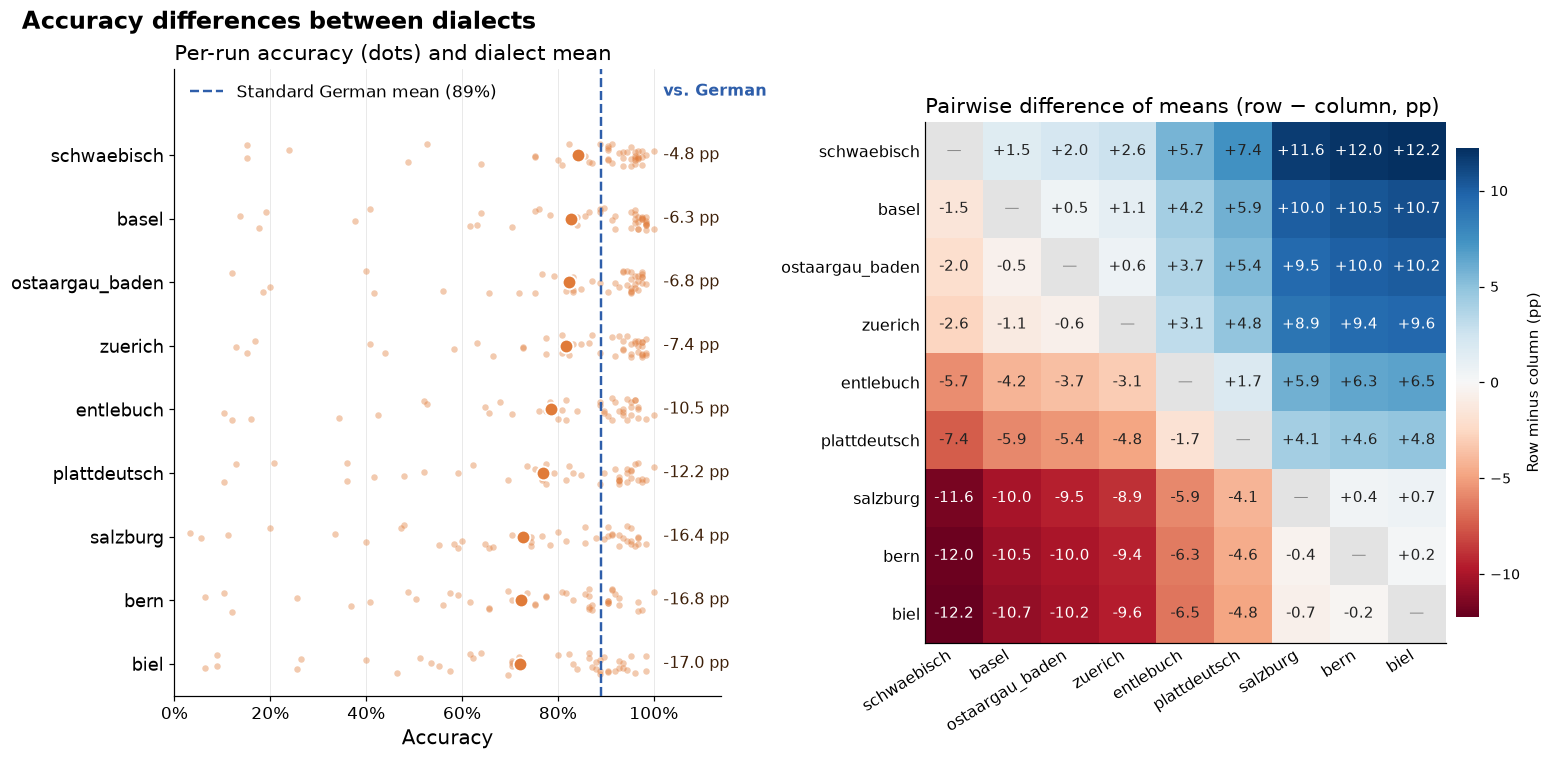

In [25]:
# Chart 2b: accuracy differences between dialects.
# Left: per-run accuracy per dialect. Right: mean difference for every dialect pair.
dialect_names = {c: c.removeprefix("mgsm_").removesuffix("_complete") for c in dialect_cols}
dialect_mean = acc[dialect_cols].mean().sort_values(ascending=False)
order = dialect_mean.index.tolist()
german_mean = acc["de"].mean()

fig, (ax_lvl, ax_dif) = plt.subplots(
    1, 2, figsize=(14, 6.8), gridspec_kw={"width_ratios": [1.05, 1]},
    layout="constrained",
)

# Left: per-run accuracy per dialect, with the dialect mean and the German reference.
y = np.arange(len(order))
rng = np.random.default_rng(0)
for yi, column in zip(y, order):
    values = acc[column].to_numpy()
    ax_lvl.scatter(values, yi + rng.uniform(-0.18, 0.18, len(values)),
                   s=18, color=DIALECT_COLOR, alpha=0.40, linewidth=0, zorder=2)
    ax_lvl.scatter(dialect_mean[column], yi, s=80, color=DIALECT_COLOR,
                   edgecolor="white", linewidth=1.2, zorder=4)
    gap = (dialect_mean[column] - german_mean) * 100
    ax_lvl.text(1.02, yi, f"{gap:+.1f} pp", va="center", ha="left",
                fontsize=10.5, color="#3D1F08")

ax_lvl.axvline(german_mean, color=DE_COLOR, linestyle="--", linewidth=1.6, zorder=3,
               label=f"Standard German mean ({german_mean:.0%})")
ax_lvl.text(1.02, -1.0, "vs. German", va="center", ha="left",
            fontsize=10.5, fontweight="bold", color=DE_COLOR)
ax_lvl.set_yticks(y)
ax_lvl.set_yticklabels([dialect_names[c] for c in order], fontsize=11.5)
ax_lvl.set_ylim(len(order) - 0.5, -1.35)  # top band holds the legend and column header
ax_lvl.set_xlim(0, 1.14)
ax_lvl.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax_lvl.set_xlabel("Accuracy", fontsize=13)
ax_lvl.grid(axis="x", color="#E3E3E3", linewidth=0.5)
ax_lvl.set_axisbelow(True)
ax_lvl.tick_params(axis="x", labelsize=11)
ax_lvl.legend(loc="upper left", frameon=False, fontsize=11)
ax_lvl.set_title("Per-run accuracy (dots) and dialect mean", loc="left", fontsize=14)

# Right: every pairwise difference between dialect means.
means_pp = dialect_mean.to_numpy() * 100
diff = means_pp[:, None] - means_pp[None, :]
masked = np.ma.masked_array(diff, np.eye(len(order), dtype=bool))
cmap = plt.get_cmap("RdBu").copy()
cmap.set_bad("#E3E3E3")
vmax = np.abs(diff).max()
image = ax_dif.imshow(masked, cmap=cmap, vmin=-vmax, vmax=vmax)

for i in range(len(order)):
    for j in range(len(order)):
        if i == j:
            ax_dif.text(j, i, "—", ha="center", va="center", fontsize=10, color="#888888")
            continue
        value = diff[i, j]
        ax_dif.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=10,
                    color="white" if abs(value) > 0.62 * vmax else "#222222")

ax_dif.set_xticks(range(len(order)))
ax_dif.set_xticklabels([dialect_names[c] for c in order], rotation=32, ha="right", fontsize=10.5)
ax_dif.set_yticks(range(len(order)))
ax_dif.set_yticklabels([dialect_names[c] for c in order], fontsize=10.5)
ax_dif.tick_params(length=0)
ax_dif.set_title("Pairwise difference of means (row − column, pp)", loc="left", fontsize=14)

bar = fig.colorbar(image, ax=ax_dif, fraction=0.045, pad=0.02)
bar.set_label("Row minus column (pp)", fontsize=10)
bar.ax.tick_params(labelsize=9)
bar.outline.set_visible(False)

fig.suptitle("Accuracy differences between dialects", x=0.01, ha="left",
             fontsize=16, fontweight="bold")

svg_path = ROOT / "images" / "dialect_differences.svg"
svg_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(svg_path, bbox_inches="tight")
print(f"saved {svg_path.relative_to(ROOT)}")

plt.show()

In [7]:
# xact parameter counts from run_info.jsonl, grouped by family.
# Single-size (Qwen 3.8) and undisclosed-size (Claude, Codex) families are skipped.
FAMILY_PREFIXES = {
    "Gemma 4": "gemma4-",
    "DeepSeek-R1": "deepseek-r1-",
    "Qwen 3.5": "qwen3.5-",
    "Mistral": "mistral-",
    "Ministral 3": "ministral-3-",
    "Apertus": "apertus-",
}


def parse_params(size):
    """Turn Ollama's size string into billions of parameters."""
    if not size:
        return np.nan
    size = str(size).strip()
    if size.endswith("B"):
        return float(size[:-1])
    if size.endswith("M"):
        return float(size[:-1]) / 1000
    return float(size) / 1e9


def family_of(model):
    for family, prefix in FAMILY_PREFIXES.items():
        if model.startswith(prefix):
            return family
    return None


infos = []
for path in sorted((ROOT / "results").glob("*/*/run_info.jsonl")):
    info = json.loads(path.read_text(encoding="utf-8").splitlines()[0])
    infos.append({
        "model": info["model"],
        "thinking": info["thinking"],
        "params": parse_params(info.get("size")),
    })
info = pd.DataFrame(infos).drop_duplicates(["model", "thinking"])

traj = acc.merge(info, on=["model", "thinking"], how="left")
traj["family"] = traj["model"].map(family_of)
traj = traj.dropna(subset=["family", "params"])

# One point per model: average the thinking modes it was run in.
traj = traj.groupby(["family", "model", "params"], as_index=False)[["de", "dialects"]].mean()

print(traj.groupby("family")["model"].nunique().to_string())

family
Apertus        2
DeepSeek-R1    5
Gemma 4        5
Ministral 3    3
Mistral        3
Qwen 3.5       6


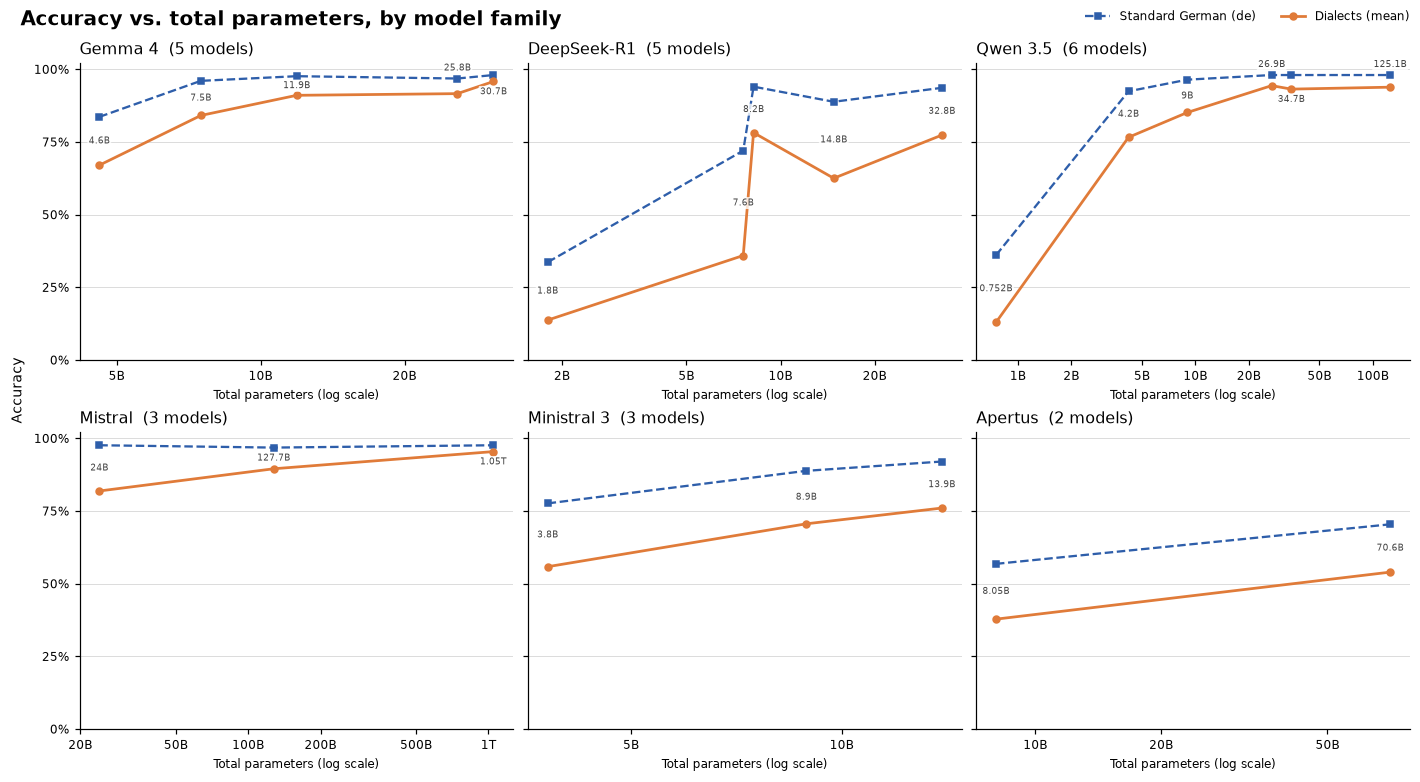

In [8]:
# Chart 3: accuracy vs. exact parameter count, one panel per family.
# Values are averaged over thinking modes; MoE models use total parameters.
FAMILY_ORDER = ["Gemma 4", "DeepSeek-R1", "Qwen 3.5", "Mistral", "Ministral 3", "Apertus"]
PARAM_TICKS = [0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]


def fmt_params(value, _):
    if value >= 1000:
        return f"{value / 1000:g}T"
    if value >= 1:
        return f"{value:g}B"
    return f"{value * 1000:g}M"


def fmt_exact(params):
    text = f"{params:.3f}" if params < 1 else f"{params:.2f}"
    text = text.rstrip("0").rstrip(".")
    return f"{params / 1000:g}T" if params >= 1000 else f"{text}B"


fig, axes = plt.subplots(2, 3, figsize=(12.8, 7.0), sharey=True, layout="constrained")

for ax, family in zip(axes.flat, FAMILY_ORDER):
    sub = traj[traj["family"] == family].sort_values("params")
    ax.plot(sub["params"], sub["de"], linestyle="--", marker="s", markersize=4.5,
            linewidth=1.5, color=DE_COLOR, label="Standard German (de)")
    ax.plot(sub["params"], sub["dialects"], linestyle="-", marker="o", markersize=4.5,
            linewidth=1.8, color=DIALECT_COLOR, label="Dialects (mean)")

    for i, (_, row) in enumerate(sub.iterrows()):
        top = max(row["de"], row["dialects"])
        bottom = min(row["de"], row["dialects"])
        if top - bottom >= 0.06:
            y, va = (top + bottom) / 2, "center"
        elif i % 2 == 1:
            y, va = top + 0.02, "bottom"
        else:
            y, va = bottom - 0.02, "top"
        ax.text(row["params"], y, fmt_exact(row["params"]), ha="center", va=va,
                fontsize=6, color="#444444",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white",
                          edgecolor="none", alpha=0.8), clip_on=False)

    ax.set_xscale("log")
    ax.set_title(f"{family}  ({len(sub)} models)", loc="left", fontsize=10.5)
    ax.set_ylim(0, 1.02)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
    ax.set_xticks([
        tick for tick in PARAM_TICKS
        if sub["params"].min() * 0.7 <= tick <= sub["params"].max() * 1.3
    ])
    ax.xaxis.set_major_formatter(FuncFormatter(fmt_params))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(axis="y", color="#D9D9D9", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=8)
    ax.set_xlabel("Total parameters (log scale)", fontsize=8)

for ax in axes[:, 0]:
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
fig.supylabel("Accuracy", fontsize=9)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper right", ncol=2, frameon=False, fontsize=8)
fig.suptitle("Accuracy vs. total parameters, by model family", x=0.01, ha="left",
             fontsize=13, fontweight="bold")

plt.show()

In [9]:
# Chart 4 data: estimate thinking tokens from the saved reasoning text (characters / 3.5).
# Raw token counts were not stored. Thinking modes are averaged; runs without reasoning are omitted.

TOKENS_PER_CHAR = 1 / 3.5
TOKEN_FAMILIES = {
    "Gemma 4": ("gemma4-", "#3B6FB6"),
    "DeepSeek-R1": ("deepseek-r1-", "#C0392B"),
    "Qwen 3.5": ("qwen3.5-", "#2E8B57"),
    "Qwen 3.8": ("qwen3.8-", "#8E44AD"),
    "Mistral": ("mistral-", "#B7791F"),
}


def token_family(model):
    for family, (prefix, _) in TOKEN_FAMILIES.items():
        if model.startswith(prefix):
            return family
    return None


file_tokens = []
for path in sorted((ROOT / "results").glob("*/*/*.tsv")):
    reasoning = pd.read_csv(path, sep="\t", usecols=["reasoning"])["reasoning"].fillna("")
    file_tokens.append({
        "model": path.parent.parent.name,
        "thinking": path.parent.name.removeprefix("thinking-"),
        "file": path.stem,
        "tokens": reasoning.str.len().mean() * TOKENS_PER_CHAR,
    })
file_tokens = pd.DataFrame(file_tokens)

de_tokens = (file_tokens[file_tokens["file"] == "de"]
             .groupby(["model", "thinking"])["tokens"].mean().rename("tok_de"))
dialect_tokens = (file_tokens[file_tokens["file"] != "de"]
                  .groupby(["model", "thinking"])["tokens"].mean().rename("tok_dial"))
tokens = pd.concat([de_tokens, dialect_tokens], axis=1).reset_index()

token_acc = acc[["model", "thinking", "de", "dialects"]].merge(
    tokens, on=["model", "thinking"], how="left")
token_acc["family"] = token_acc["model"].map(token_family)
token_acc = token_acc.dropna(subset=["family", "tok_de", "tok_dial"])
token_acc = token_acc[(token_acc["tok_de"] > 0) | (token_acc["tok_dial"] > 0)]

# One point per model: average its thinking modes.
token_acc = (token_acc.groupby(["family", "model"], as_index=False)
             [["tok_de", "tok_dial", "de", "dialects"]].mean())

print(f"{len(token_acc)} models with stored reasoning")

/tmp/ipykernel_8842/3303416812.py:23: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  reasoning = pd.read_csv(path, sep="\t", usecols=["reasoning"])["reasoning"].fillna("")
/tmp/ipykernel_8842/3303416812.py:23: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  reasoning = pd.read_csv(path, sep="\t", usecols=["reasoning"])["reasoning"].fillna("")
/tmp/ipykernel_8842/3303416812.py:23: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  reasoning = pd.read_csv(path, sep="\t", usecols=["reasoning"])["reasoning"].fillna("")
/tmp/ipykernel_8842/33

18 models with stored reasoning


/tmp/ipykernel_8842/3303416812.py:23: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  reasoning = pd.read_csv(path, sep="\t", usecols=["reasoning"])["reasoning"].fillna("")
/tmp/ipykernel_8842/3303416812.py:23: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  reasoning = pd.read_csv(path, sep="\t", usecols=["reasoning"])["reasoning"].fillna("")
/tmp/ipykernel_8842/3303416812.py:23: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  reasoning = pd.read_csv(path, sep="\t", usecols=["reasoning"])["reasoning"].fillna("")
/tmp/ipykernel_8842/33

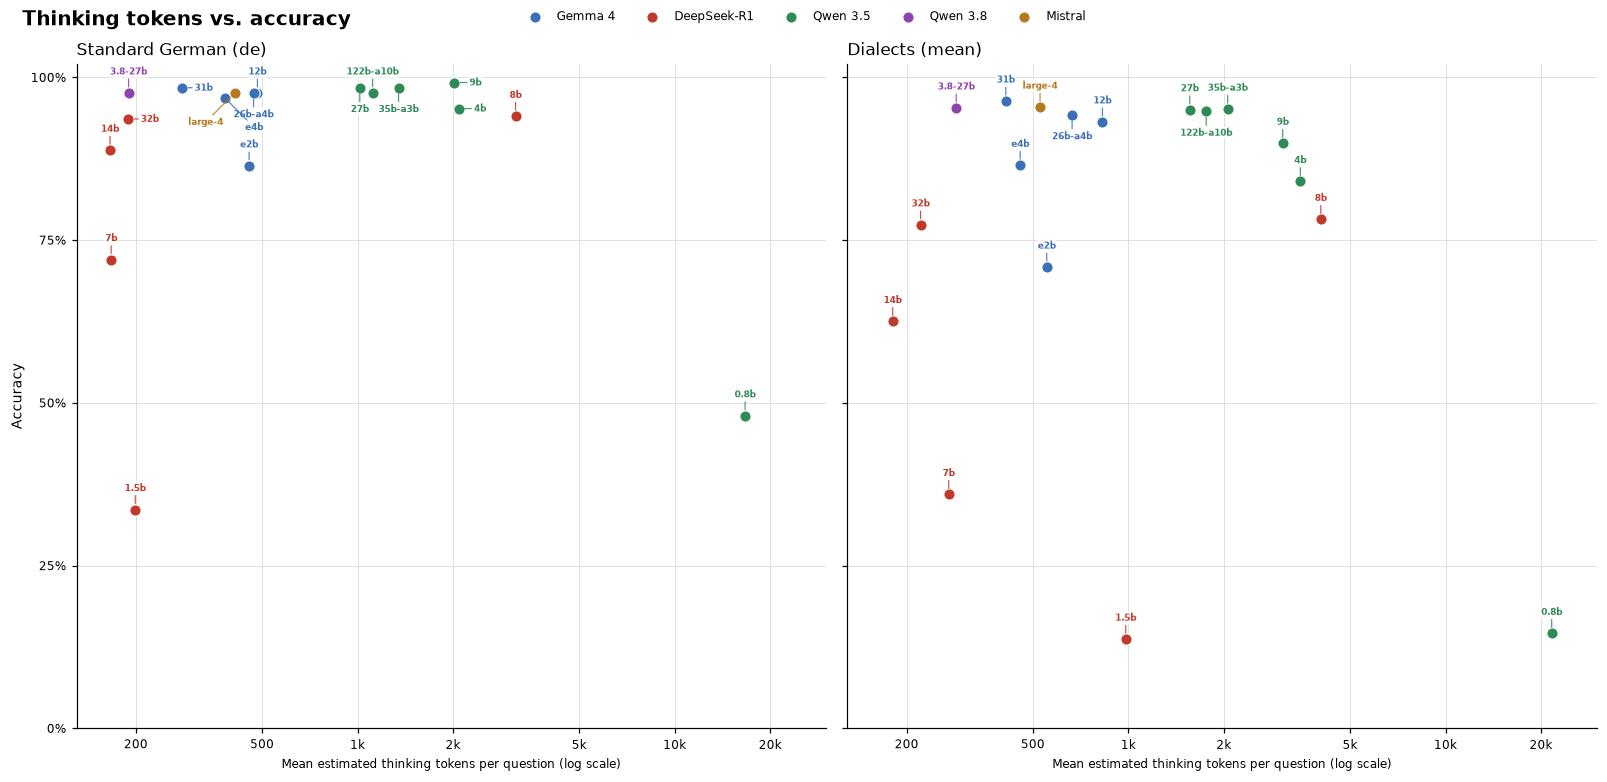

In [10]:
# Chart 4: mean estimated thinking tokens per question vs. accuracy.
# Every model is labelled; labels are moved around their point to avoid overlaps.

TOKEN_SHORT = {
    "gemma4-e2b": "e2b", "gemma4-e4b": "e4b", "gemma4-12b": "12b",
    "gemma4-26b-a4b": "26b-a4b", "gemma4-31b": "31b",
    "deepseek-r1-1.5b": "1.5b", "deepseek-r1-7b": "7b", "deepseek-r1-8b": "8b",
    "deepseek-r1-14b": "14b", "deepseek-r1-32b": "32b",
    "qwen3.5-0.8b": "0.8b", "qwen3.5-4b": "4b", "qwen3.5-9b": "9b",
    "qwen3.5-27b": "27b", "qwen3.5-35b-a3b": "35b-a3b", "qwen3.5-122b-a10b": "122b-a10b",
    "qwen3.8-27b": "3.8-27b", "mistral-large-4": "large-4",
}


def add_labels(ax, subset, xcol, ycol, fontsize=6):
    """Place every label near its point, avoiding old labels and markers."""
    ax.figure.canvas.draw()
    renderer = ax.figure.canvas.get_renderer()
    font = FontProperties(size=fontsize, weight="bold")
    scale = ax.figure.dpi / 72
    axes_box = ax.get_window_extent(renderer)
    points = [ax.transData.transform((row[xcol], row[ycol])) for _, row in subset.iterrows()]
    placed = []
    directions = [(0, 1), (1, 0), (0, -1), (-1, 0), (1, 1), (-1, 1), (1, -1), (-1, -1)]
    radii = [14, 19, 25, 32, 40, 50, 62, 76, 90]

    # Highest points first: they have the least room above them.
    order = sorted(range(len(points)), key=lambda i: -points[i][1])
    for i in order:
        row = subset.iloc[i]
        text = TOKEN_SHORT.get(row["model"], row["model"])
        px, py = points[i]
        tw, th, _ = renderer.get_text_width_height_descent(text, font, False)
        bw, bh = tw + 4, th + 4
        chosen = None
        for radius in radii:
            for dx, dy in directions:
                rx, ry = dx * radius * scale, dy * radius * scale
                box = Bbox.from_bounds(px + rx - bw / 2, py + ry - bh / 2, bw, bh)
                if (box.x0 < axes_box.x0 + 1 or box.x1 > axes_box.x1 - 1
                        or box.y0 < axes_box.y0 + 1 or box.y1 > axes_box.y1 - 1):
                    continue
                if any(box.overlaps(other) for other in placed):
                    continue
                if any(box.x0 < mx + 5 and box.x1 > mx - 5
                       and box.y0 < my + 5 and box.y1 > my - 5 for mx, my in points):
                    continue
                chosen = (dx * radius, dy * radius, radius, box)
                break
            if chosen:
                break
        if not chosen:
            chosen = (0, 12, 12, Bbox.from_bounds(px - bw / 2, py + 12 * scale - bh / 2, bw, bh))
        xoff, yoff, radius, box = chosen
        color = TOKEN_FAMILIES[row["family"]][1]
        ax.annotate(text, (row[xcol], row[ycol]), xytext=(xoff, yoff),
                    textcoords="offset points", ha="center", va="center",
                    fontsize=fontsize, color=color, fontweight="bold", zorder=5,
                    bbox=dict(boxstyle="round,pad=0.1", facecolor="white",
                              edgecolor="none", alpha=0.9),
                    arrowprops=dict(arrowstyle="-", color=color, linewidth=0.8,
                                    alpha=0.85, shrinkA=1, shrinkB=4))
        placed.append(box)


fig, axes = plt.subplots(1, 2, figsize=(14.5, 7.0), sharey=True, sharex=True,
                         layout="constrained")

for ax, metric, token_col, title in (
    (axes[0], "de", "tok_de", "Standard German (de)"),
    (axes[1], "dialects", "tok_dial", "Dialects (mean)"),
):
    for family, (_, color) in TOKEN_FAMILIES.items():
        sub = token_acc[token_acc["family"] == family]
        ax.scatter(sub[token_col], sub[metric], s=55, color=color,
                   edgecolor="white", linewidth=0.8, label=family, zorder=3)

    ax.set_xscale("log")
    ax.set_xlim(130, 30000)
    ax.set_xticks([200, 500, 1000, 2000, 5000, 10000, 20000])
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda value, _: f"{value / 1000:g}k" if value >= 1000 else f"{value:g}"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_ylim(0, 1.02)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
    ax.grid(color="#DDDDDD", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Mean estimated thinking tokens per question (log scale)", fontsize=8)
    ax.tick_params(labelsize=8)

axes[0].set_ylabel("Accuracy", fontsize=9)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=5, frameon=False, fontsize=8)
fig.suptitle("Thinking tokens vs. accuracy", x=0.01, ha="left", fontsize=13, fontweight="bold")

# The layout is final now, so label placement uses the real panel geometry.
fig.canvas.draw()
for ax, token_col, metric in ((axes[0], "tok_de", "de"), (axes[1], "tok_dial", "dialects")):
    add_labels(ax, token_acc, token_col, metric, fontsize=6)

plt.show()
